# Streaming tokens to the browser

A bank's call-centre agents ask a helper what to do while a customer waits on the line. The helper's first route
waits for the whole model answer, so the agent stares at a blank box. In this notebook you run both routes with
FastAPI, read the stream with your own parser (the lesson's `fetch` reader, written in Python), compare when the
first word arrives, and stop the server in the middle of an answer.

About 10 minutes. Run the cells from top to bottom. Everything runs on a free CPU runtime, with no account and no key.

There is no model server in Colab. The lesson ran a small open model (gemma3:270m in Ollama, temperature 0, seed 7,
on 2026-11-13). Here the helper's `model_tokens` **replays** that model's recorded tokens at the times the
lesson's server log recorded them. Everything after `model_tokens` is real: a real FastAPI server, a real HTTP
connection, a real parser, and a real crash.

## 1. Install the versions the lesson ran

The next cell installs FastAPI 0.162.6 (its `EventSourceResponse` needs 0.135.0 or later), Starlette 1.10.0,
Pydantic 2.14.3, httpx 0.28.1 and uvicorn 0.54.0, the server that runs the app.

**Look for:** no error. pip may print a few lines about other packages; you can ignore them.

In [1]:
%pip install -q fastapi==0.162.6 starlette==1.10.0 pydantic==2.14.3 httpx==0.28.1 uvicorn==0.54.0

Note: you may need to restart the kernel to use updated packages.


## 2. The model's recorded tokens

The agent's question, and the 79 tokens the model wrote, in order, with the millisecond each one left the model
(from the lesson's server log, `stream.server.txt`). The cell saves them to `recorded.json` for the server to replay.

**Look for:** 79 tokens, the first at 199 ms, the last at 2245 ms. The joined answer has four numbered steps.
Some tokens are tiny: a full stop, a space, a single digit, a line break.

In [2]:
import json

QUESTION = "The customer sees a card payment of 42.90 EUR to an online shop they do not recognise. What do I do?"

TOKENS = [
    "1", ".", " Confirm", " the", " payment", " with", " the", " customer", ":", " amount",
    ",", " date", ",", " shop", " name", ".", "\n", "2", ".", " Ask",
    " whether", " anyone", " else", " uses", " the", " card", ".", "\n", "3", ".",
    " If", " the", " customer", " still", " does", " not", " recognise", " it", ",", " block",
    " the", " card", " and", " order", " a", " new", " one", ".", "\n", "4",
    ".", " Open", " a", " dispute", ";", " the", " customer", " gets", " an", " answer",
    " within", " ", "1", "0", " working", " days", ".", " Never", " ask", " for",
    " the", " full", " card", " number", " or", " the", " PIN", ".", "\n",
]
SENT_MS = [
    199, 219, 240, 263, 291, 332, 376, 425, 465, 499, 527, 554, 579, 612, 634,
    658, 682, 706, 729, 753, 777, 809, 832, 860, 890, 917, 945, 972, 999, 1029,
    1053, 1078, 1103, 1126, 1148, 1172, 1194, 1221, 1241, 1264, 1289, 1313, 1337, 1362, 1389,
    1416, 1454, 1478, 1505, 1530, 1556, 1580, 1604, 1628, 1652, 1675, 1699, 1722, 1745, 1769,
    1794, 1818, 1843, 1871, 1898, 1923, 1950, 1974, 2000, 2025, 2050, 2076, 2100, 2124, 2148,
    2172, 2196, 2221, 2245,
]

json.dump({"tokens": TOKENS, "sent_ms": SENT_MS}, open("recorded.json", "w"))
print(f"{len(TOKENS)} tokens, the first at {SENT_MS[0]} ms, the last at {SENT_MS[-1]} ms")
print("tokens 15 to 19:", TOKENS[14:19])
print()
print("".join(TOKENS))

79 tokens, the first at 199 ms, the last at 2245 ms
tokens 15 to 19: [' name', '.', '\n', '2', '.']

1. Confirm the payment with the customer: amount, date, shop name.
2. Ask whether anyone else uses the card.
3. If the customer still does not recognise it, block the card and order a new one.
4. Open a dispute; the customer gets an answer within 10 working days. Never ask for the full card number or the PIN.



## 3. The helper app, with both routes

The next cell writes `helper_app.py`. Both routes are the lesson's code, line for line. Only `model_tokens` is
different: in the lesson it read the model server's own stream; here it waits until each token's recorded time and
yields it. Every token is logged with the milliseconds since the request arrived, as in the lesson.

- **Route 1, `/answer`:** the list comprehension collects every token, then `return` sends one JSON body.
- **Route 2, `/answer/stream`:** each `yield ServerSentEvent(...)` becomes one event on the wire, at once. `data`
  is JSON-encoded for you; `raw_data` is sent as it is.

**Look for:** `Writing helper_app.py`.

In [3]:
%%writefile helper_app.py
"""The call-centre helper behind an API. Two routes over the same model."""
import asyncio, json, sys, time
from collections.abc import AsyncIterable
from pathlib import Path

from fastapi import FastAPI
from fastapi.sse import EventSourceResponse, ServerSentEvent
from pydantic import BaseModel

RECORDED = json.loads(Path("recorded.json").read_text())
app = FastAPI()


class Question(BaseModel):
    text: str


def log(route, t0, what):
    print(f"server {route} {round((time.monotonic() - t0) * 1000)} ms {what}", file=sys.stderr, flush=True)


async def model_tokens(question: str, route: str):
    # Replay: wait until each token's recorded time, then yield it, as the model did.
    t0 = time.monotonic()
    for token, at_ms in zip(RECORDED["tokens"], RECORDED["sent_ms"]):
        await asyncio.sleep(max(0, at_ms / 1000 - (time.monotonic() - t0)))
        log(route, t0, f"token {json.dumps(token)}")
        yield token
    log(route, t0, "model finished")


@app.post("/answer")
async def answer(question: Question) -> dict:
    text = "".join([token async for token in model_tokens(question.text, "/answer")])
    return {"answer": text}


@app.post("/answer/stream", response_class=EventSourceResponse)
async def answer_stream(question: Question) -> AsyncIterable[ServerSentEvent]:
    async for token in model_tokens(question.text, "/answer/stream"):
        yield ServerSentEvent(data=token, event="token")
    yield ServerSentEvent(raw_data="[DONE]", event="done")

Writing helper_app.py


## 4. Start the server

`start_server` runs the app with uvicorn in its own process, on port 57410, and waits until it answers. The
server's log goes to `server.log`; `server_log(n)` prints its last n lines. A separate process matters later: in
step 10 you stop it in the middle of an answer, like a deploy that restarts the server.

**Look for:** `server is up at http://127.0.0.1:57410`.

In [4]:
import subprocess, sys, time
import httpx

APP = "http://127.0.0.1:57410"

def start_server():
    proc = subprocess.Popen([sys.executable, "-m", "uvicorn", "helper_app:app", "--port", "57410", "--log-level", "warning"],
                            stderr=open("server.log", "w"))
    for _ in range(100):
        try:
            httpx.get(APP + "/docs")
            break
        except httpx.HTTPError:
            time.sleep(0.2)
    print("server is up at", APP)
    return proc

def server_log(n):
    print("\n".join(open("server.log").read().splitlines()[-n:]))

server = start_server()

server is up at http://127.0.0.1:57410


## 5. Route 1: the whole answer at once

The cell posts the question to `/answer` and measures when the response arrives. This is what the agent's page
did before: nothing to show until the body is there.

**Look for:** the body arrives after about **2.3 s**, as one JSON body of about 328 bytes, with
`content-type: application/json`. The server log shows why: the model's last token left at about 2245 ms and the
model finished just after. The agent saw nothing before that.

In [5]:
t0 = time.perf_counter()
res = httpx.post(APP + "/answer", json={"text": QUESTION}, timeout=None)
whole_s = time.perf_counter() - t0

print(f"route 1: the body arrived after {whole_s:.2f} s, {len(res.content)} bytes, content-type: {res.headers['content-type']}")
print()
print(res.json()["answer"])
print("last lines of the server log:")
server_log(3)

route 1: the body arrived after 2.26 s, 328 bytes, content-type: application/json

1. Confirm the payment with the customer: amount, date, shop name.
2. Ask whether anyone else uses the card.
3. If the customer still does not recognise it, block the card and order a new one.
4. Open a dispute; the customer gets an answer within 10 working days. Never ask for the full card number or the PIN.

last lines of the server log:
server /answer 2221 ms token "."
server /answer 2245 ms token "\n"
server /answer 2246 ms model finished


## 6. Route 2: what travels over the wire

Now the same question to `/answer/stream`. The cell keeps every network piece (a **chunk**) exactly as it came,
with its arrival time, and prints the response headers. You wrote no header code in step 3.

**Look for:** `content-type: text/event-stream; charset=utf-8`, `cache-control: no-cache` and
`x-accel-buffering: no`, all set by FastAPI. The first chunk arrives after about **0.2 s**:
`'event: token\ndata: "1"\n\n'`. Each event is an `event:` line and a `data:` line, and an empty line (two `\n` in a
row) ends it. In total about 80 chunks and 2158 bytes, much more than route 1's body, and the last chunk is the
done event.

In [6]:
t0 = time.perf_counter()
ms = lambda: round((time.perf_counter() - t0) * 1000)

with httpx.stream("POST", APP + "/answer/stream", json={"text": QUESTION}, timeout=None) as res:
    for name in ["content-type", "cache-control", "x-accel-buffering"]:
        print(f"{name}: {res.headers.get(name)}")
    chunks = [(ms(), chunk) for chunk in res.iter_raw()]

print()
for at, chunk in chunks[:3]:
    print(f"chunk at {at} ms: {chunk.decode()!r}")
print("...")
print(f"chunk at {chunks[-1][0]} ms: {chunks[-1][1].decode()!r}")
print(f"{len(chunks)} chunks, {sum(len(c) for _, c in chunks)} bytes in total")

content-type: text/event-stream; charset=utf-8
cache-control: no-cache
x-accel-buffering: no



chunk at 223 ms: 'event: token\ndata: "1"\n\n'
chunk at 244 ms: 'event: token\ndata: "."\n\n'
chunk at 266 ms: 'event: token\ndata: " Confirm"\n\n'
...
chunk at 2271 ms: 'event: done\ndata: [DONE]\n\n'
80 chunks, 2158 bytes in total


## 7. Your parser: the lesson's fetch reader, in Python

`feed` is the lesson's reader, line for line: add the text to `buffer`, split at empty lines, keep the last piece
(it may be half an event), and handle every complete event. `read_stream` reads the response chunk by chunk, like
`reader.read()` in the browser. Python's incremental decoder plays the part of
`decoder.decode(value, { stream: true })`: it keeps a character whose bytes were split across two chunks.

`read_stream` prints the first three and the last two events with their arrival times, then `finished`.

**Look for:** the first token event at about **0.2 s** and the done event at about **2.3 s**. `finished=True`,
79 tokens, and `buffer_left=''`: nothing half-made was left over. The answer printed at the end has its four lines.

In [7]:
import codecs, re

def new_state():
    return {"buffer": "", "answer": "", "finished": False}

def feed(state, text, decode=json.loads):
    state["buffer"] += text
    events = state["buffer"].split("\n\n")
    state["buffer"] = events.pop()          # the last piece may be half an event
    parsed = []
    for ev in events:
        type_ = re.search(r"^event: (.*)$", ev, re.M)
        data = re.search(r"^data: (.*)$", ev, re.M)
        type_, data = type_ and type_[1], data and data[1]
        if type_ == "token": state["answer"] += decode(data)
        if type_ == "done": state["finished"] = True
        parsed.append((type_, data))
    return parsed

def read_stream(url, kill_after=None, proc=None):
    state, log, tokens = new_state(), [], 0
    decoder = codecs.getincrementaldecoder("utf-8")()
    t0 = time.perf_counter()
    ms = lambda: round((time.perf_counter() - t0) * 1000)
    try:
        with httpx.stream("POST", url, json={"text": QUESTION}, timeout=None) as res:
            print(f"head {ms()} ms status={res.status_code}")
            for value in res.iter_raw():
                for type_, data in feed(state, decoder.decode(value)):
                    log.append((ms(), type_, data))
                    tokens += type_ == "token"
                    if kill_after and tokens == kill_after:
                        proc.kill()
                        print(f"killed the server after token {tokens}, at {ms()} ms")
    except httpx.HTTPError as err:
        print(f"error {ms()} ms {type(err).__name__}: {err}")
    for row in log[:3] + [None] + log[-2:]:
        print("..." if row is None else "event {} ms type={} data={}".format(*row))
    print(f"end {ms()} ms finished={state['finished']} tokens={tokens} buffer_left={state['buffer']!r}")
    return state, log

state, log = read_stream(APP + "/answer/stream")
print()
print(state["answer"])

head 7 ms status=200


event 208 ms type=token data="1"
event 227 ms type=token data="."
event 248 ms type=token data=" Confirm"
...
event 2254 ms type=token data="\n"
event 2254 ms type=done data=[DONE]
end 2255 ms finished=True tokens=79 buffer_left=''

1. Confirm the payment with the customer: amount, date, shop name.
2. Ask whether anyone else uses the card.
3. If the customer still does not recognise it, block the card and order a new one.
4. Open a dispute; the customer gets an answer within 10 working days. Never ask for the full card number or the PIN.



## 8. The two routes on one time line

Each tick on the lower lane is one token event reaching your parser (step 7). The mark on the upper lane is when
route 1's body arrived (step 5).

**Look for:** route 2's first tick at about 0.2 s, route 1's mark at about 2.3 s: the first word came roughly
**ten times sooner** (the exact number moves a little from run to run). The last tick of route 2 is close to route 1's mark: the full answer took about as long
either way. Streaming moved the wait from the last token to the first.

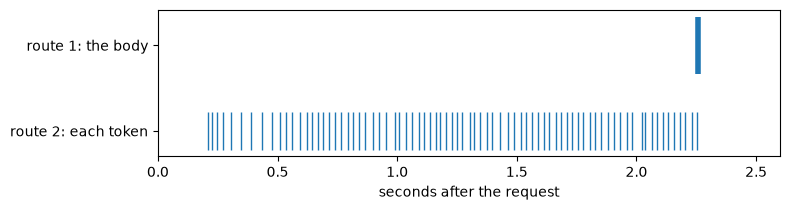

first word: route 2 at 0.21 s, route 1 at 2.26 s, about 11 times sooner
whole answer: route 2 done at 2.25 s, route 1 at 2.26 s


In [8]:
import matplotlib.pyplot as plt

token_s = [at / 1000 for at, type_, _ in log if type_ == "token"]
done_s = [at / 1000 for at, type_, _ in log if type_ == "done"][0]

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.vlines(token_s, 0.1, 0.5, linewidth=1)
ax.vlines([whole_s], 0.9, 1.5, linewidth=4)
ax.set_yticks([0.3, 1.2], ["route 2: each token", "route 1: the body"])
ax.set_xlim(0, 2.6)
ax.set_xlabel("seconds after the request")
plt.tight_layout()
plt.show()

print(f"first word: route 2 at {token_s[0]:.2f} s, route 1 at {whole_s:.2f} s, about {round(whole_s / token_s[0])} times sooner")
print(f"whole answer: route 2 done at {done_s:.2f} s, route 1 at {whole_s:.2f} s")

## 9. A line break inside a token

Token 17 of the answer is a line break, between step 1 and step 2. The server JSON-encodes each token, so the line
break travels as the two characters `\n` inside quotes, and the data line stays one line. `json.loads` (the
browser's `JSON.parse`) turns it back.

**Look for:** the raw event `event: token`, `data: "\n"`, then an empty line. The parsed token is `'\n'`, one
character. The answer from step 7 is exactly the recorded answer: `True`.

In [9]:
nl_chunk = next(c.decode() for _, c in chunks if c.decode() == 'event: token\ndata: "\\n"\n\n')
print("raw event, as it came:")
print(nl_chunk.replace("\n", "\u21b5\n"))
print("parsed token:", repr(json.loads(nl_chunk.split("data: ")[1].strip())))
print("answer from step 7 == recorded answer:", state["answer"] == "".join(TOKENS))

raw event, as it came:
event: token↵
data: "\n"↵
↵

parsed token: '\n'
answer from step 7 == recorded answer: True


## 10. Broken on purpose: the server stops mid-answer

During a deploy the helper's server is restarted while answers are streaming. The cell reproduces it:
`read_stream` kills the server process the moment it has the 30th token. The read fails, and the
`try`/`except` in `read_stream` catches it, like the `try`/`catch` around the browser's reading loop.

**Look for:** `status=200` at the start: a status cannot change once the body has started. Then an error line,
`RemoteProtocolError: peer closed connection without sending complete message body`. `finished=False` and
`tokens=30`: no done event came. The text so far ends at `3.`, and the cell marks it as cut off instead of
showing it as a normal answer.

In [10]:
state, _ = read_stream(APP + "/answer/stream", kill_after=30, proc=server)
print()
print(state["answer"])
if not state["finished"]:
    print("[The answer was cut off. Ask again.]")

head 6 ms status=200


killed the server after token 30, at 1036 ms
error 1038 ms RemoteProtocolError: peer closed connection without sending complete message body (incomplete chunked read)
event 206 ms type=token data="1"
event 226 ms type=token data="."
event 248 ms type=token data=" Confirm"
...
event 1007 ms type=token data="3"
event 1036 ms type=token data="."
end 1038 ms finished=False tokens=30 buffer_left=''

1. Confirm the payment with the customer: amount, date, shop name.
2. Ask whether anyone else uses the card.
3.
[The answer was cut off. Ask again.]


## Now change it

Three small experiments. Each cell has one line marked `# <- change this`. Change it and run the cell again.
The first two feed text to your parser by hand, with no server; the third starts the server again.

### Experiment 1: a chunk that ends in the middle of an event

Nothing promises that a chunk ends where an event ends. The cell takes two real events, cuts the text at position
`CUT`, and feeds the two halves to `feed` as two chunks.

**What should change:** with `CUT = 25` the first chunk ends right after `data: " card`. No event is parsed from
it, and the half event waits in `buffer`. The second chunk brings the rest, and both events are parsed: the answer
is `' card.'` either way. Try 28 (one whole event in the first chunk) and 5: the answer stays the same, only what
waits in `buffer` changes.

In [11]:
wire = 'event: token\ndata: " card"\n\nevent: token\ndata: "."\n\n'
CUT = 25  # <- change this (try 28, or 5)

s = new_state()
for chunk in [wire[:CUT], wire[CUT:]]:
    parsed = feed(s, chunk)
    print(f"chunk {chunk!r}")
    print(f"   parsed: {parsed}   buffer: {s['buffer']!r}")
print("answer:", repr(s["answer"]))

chunk 'event: token\ndata: " card'
   parsed: []   buffer: 'event: token\ndata: " card'
chunk '"\n\nevent: token\ndata: "."\n\n'
   parsed: [('token', '" card"'), ('token', '"."')]   buffer: ''
answer: ' card.'


### Experiment 2: send the tokens without JSON

The cell builds the events for tokens 15 to 19 (`' name'`, `'.'`, the line break, `'2'`, `'.'`) as the server
would, and parses them. With `JSON_ENCODE = True` the data is JSON, as FastAPI sends it.

**What should change:** set it to `False`, so the bare token goes after `data: `. The line-break token becomes a
real line break, which, with the line break after it, makes an empty line. The event ends before its token: the
parser still counts five token events, but the line-break token arrives empty. The line break is lost, and step 1
and step 2 run together as `' name.2.'` on one line.

In [12]:
JSON_ENCODE = True  # <- change this (try False)

encode = json.dumps if JSON_ENCODE else (lambda token: token)
decode = json.loads if JSON_ENCODE else (lambda data: data)
wire = "".join(f"event: token\ndata: {encode(t)}\n\n" for t in TOKENS[14:19])

s = new_state()
parsed = feed(s, wire, decode)
print(f"{len(parsed)} token events parsed (5 were sent)")
print("tokens:", [decode(d) for _, d in parsed])
print("answer:", repr(s["answer"]))

5 token events parsed (5 were sent)
tokens: [' name', '.', '\n', '2', '.']
answer: ' name.\n2.'


### Experiment 3: stop the server at a different token

The cell starts the server again and stops it after `KILL_AFTER` tokens.

**What should change:** with 60 the answer is cut inside step 4, after `gets an answer`. It is longer, but `finished` is
still `False`: text alone cannot tell you whether an answer is whole. With `None` the server is not stopped, the
done event arrives, and `finished=True`. Only the done event proves the answer is complete.

In [13]:
KILL_AFTER = 30  # <- change this (try 60, or None)

server = start_server()
state, _ = read_stream(APP + "/answer/stream", kill_after=KILL_AFTER, proc=server)
print()
print(state["answer"] if state["finished"] else state["answer"] + "\n[The answer was cut off. Ask again.]")
server.kill()

server is up at http://127.0.0.1:57410
head 13 ms status=200


killed the server after token 30, at 1044 ms
error 1046 ms RemoteProtocolError: peer closed connection without sending complete message body (incomplete chunked read)
event 215 ms type=token data="1"
event 234 ms type=token data="."
event 254 ms type=token data=" Confirm"
...
event 1013 ms type=token data="3"
event 1044 ms type=token data="."
end 1046 ms finished=False tokens=30 buffer_left=''

1. Confirm the payment with the customer: amount, date, shop name.
2. Ask whether anyone else uses the card.
3.
[The answer was cut off. Ask again.]


## What you should see

- Step 5: route 1 prints nothing until the model has finished; then one JSON body arrives, after about 2.3 s.
- Step 6: the response of `/answer/stream` has `content-type: text/event-stream; charset=utf-8`,
  `cache-control: no-cache` and `x-accel-buffering: no`, though you set none of them.
- Steps 7 and 8: the first token event arrives long before the done event, about 0.2 s against about 2.3 s.
- Step 9: the line-break token arrives as `data: "\n"`, and the answer printed in step 7 has its line breaks back.
- Step 10: stopping the server mid-answer makes the read fail, and `finished` stays `False`.